In [1]:
import os, sys

project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.insert(0, project_root)


In [2]:
from LBP.lbp_feature_extraction import extract_lbp_features
from LBP.lbp_utils import *
from lbp_config import *
from core.process_dataset import sift_split_data
from core.evaluations import get_model_score, get_model_cm, plot_model_comparison


# Load Dataset

In [3]:
train_images, train_labels, test_images, test_labels, classes = sift_split_data(
    data_root=DATA_ROOT,
    sample_ratio=SAMPLE_RATIO,
    test_ratio=TEST_SIZE,
    shuffle_seed=RANDOM_STATE,
    load_color_images=False  
)
score_dict = {}

Total: 9600 training images, 2400 testing images


# LBP+KNN

## Score

In [4]:
clf_type = "knn"
if LOAD_MODEL and os.path.exists(f"{MODEL_DIR}/lbp_classifier_knn.pkl"):
    scaler, clf = load_lbp_model(clf_type)
else:
    scaler, clf = train_lbp_model(train_images, train_labels, classifier_type=clf_type)
print("  KNN Test Results: ")
y_test_knn, y_pred_knn, classes_knn = test_lbp_model(test_images, test_labels, scaler, clf, classes)
acc_knn, f1_knn = get_model_score(y_test_knn, y_pred_knn, classes_knn)
score_dict["LBP-KNN"] = (acc_knn, f1_knn)

  Extract training set LBP features...


  Save features to cached_features_lbp/lbp_train_features.npy
  The model has been saved as classifier_knn.pkl
  KNN Test Results: 
  Extract test set LBP features...

Model evaluation results: 
Accuracy: 0.5254
Precision: 0.5281
Recall: 0.5254
F1-score: 0.5219


## Confusion Matrix and Report


Confusion Matrix: 
[[ 86  15   7   1   5   0   2   4   7   7   3   4   7   6   6]
 [ 20  61   4  11   0   0   0  22   1   6   4   4  19   5   3]
 [ 14   4  57   0  12   5   3   5  16   5   3  10   1   6  19]
 [  3  21   1  95   0   0   0   6   0   0   1   2  14  10   7]
 [  5   0  17   1 106   4   4   0   6  15   0   0   0   1   1]
 [  0   1   0   0   6 135  12   0   2   1   0   0   0   3   0]
 [  9   1   2   0   5  21 102   0   2   1   7   0   0   5   5]
 [  7  20   4  17   1   2   0  64   2   0   6   1  13  19   4]
 [  6   1  19   1   4   2   3   1  79   6   1  15   0   4  18]
 [  1   5   3   2  11   4   1   2   7 115   0   0   1   3   5]
 [ 10  10   2   7   0   3   3   6   0   4  80   5   3  25   2]
 [ 10   1  12   9   0   0   0   4  34   0   4  80   1   2   3]
 [  2  26   0  40   0   0   0  19   1   1   1   0  57   9   4]
 [  3   5   4  11   0   1   2   9   0   1   6   0   8 108   2]
 [ 26  15  12   5   9   2   2   8   7  24   2   6   2   4  36]]

Classification Report: 
         

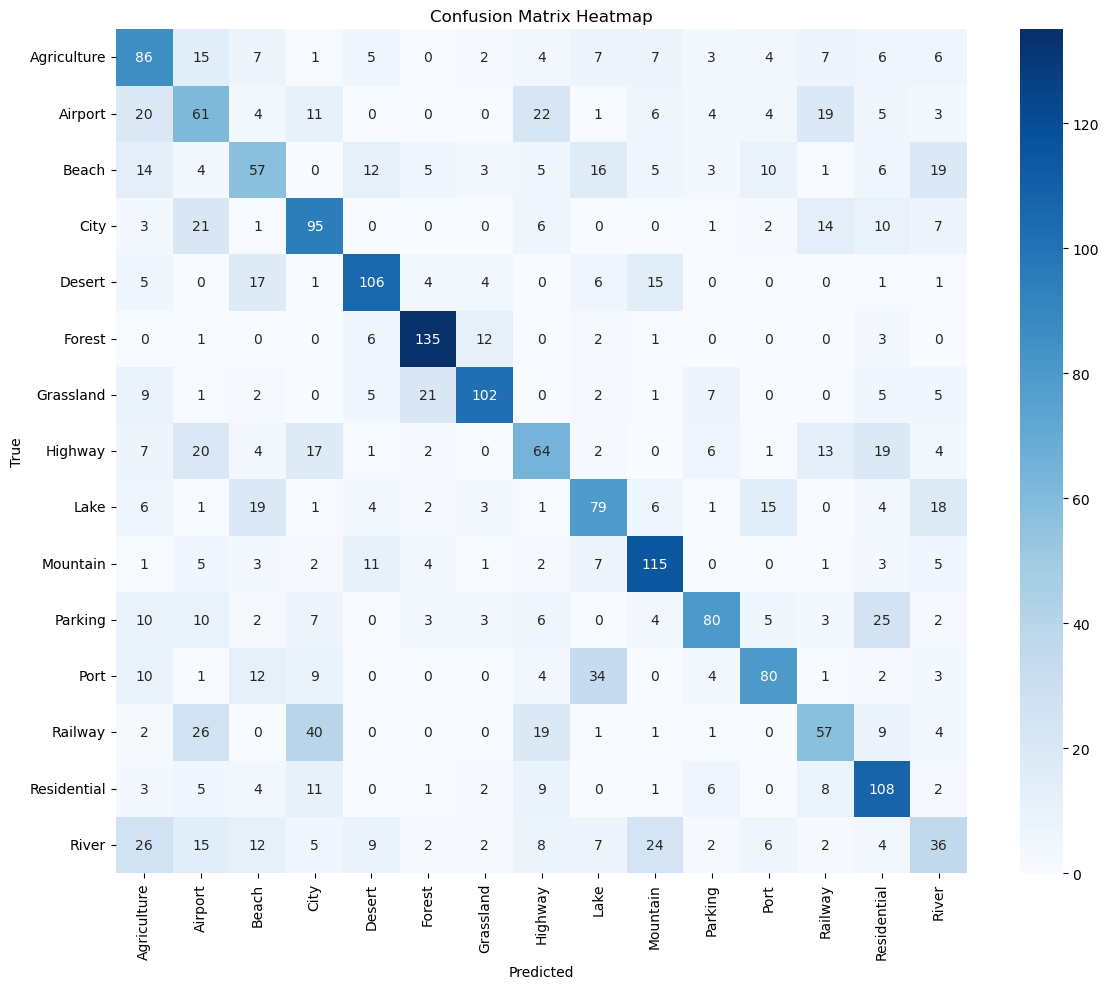

In [5]:
get_model_cm(y_test_knn, y_pred_knn, classes_knn)

# LBP+SVM

## Score

In [6]:
CLASSIFIER_TYPE = "svm"
if LOAD_MODEL and os.path.exists(f"{MODEL_DIR}/lbp_classifier_svm.pkl"):
    scaler, clf = load_lbp_model()
else:
    scaler, clf = train_lbp_model(train_images, train_labels)
print("  SVM Test Results:")

y_test_svm, y_pred_svm, classes = test_lbp_model(test_images, test_labels, scaler, clf, classes)
acc_svm, f1_svm = get_model_score(y_test_svm, y_pred_svm, classes)
score_dict["LBP-SVM"] = (acc_svm, f1_svm)


  Load cached LBP features...


  The model has been saved as classifier_svm.pkl
  SVM Test Results:
  Load cached LBP test features...

Model evaluation results: 
Accuracy: 0.6012
Precision: 0.6008
Recall: 0.6012
F1-score: 0.5982


## Confusion Matrix and Report


Confusion Matrix: 
[[ 82  16   6   3  10   0   4   5   6   5   5   1   5   0  12]
 [ 13  63   3   6   1   1   0  35   1   1   4   3  12   6  11]
 [  8   2  88   2  21   3   4   1   9   6   2   5   0   3   6]
 [  5  17   2  85   0   0   0   7   1   3   3   1  25   7   4]
 [  4   0   7   1 119   2   9   0   6  10   1   0   0   0   1]
 [  0   0   0   0   3 142  11   0   0   0   2   0   0   1   1]
 [  8   0   1   0   9  18 110   0   0   1   6   0   0   2   5]
 [  4  18   3   2   2   2   0  75   1   0   4   1  22  24   2]
 [ 10   2  14   1   5   2   4   0  85  11   1   8   0   2  15]
 [  0   0   3   1  11   2   2   1   0 135   0   0   0   1   4]
 [  3   7   2   2   0   1   5  10   0   0 102   5   1  17   5]
 [  7   2  15   4   0   0   0   2  17   0   2 101   4   2   4]
 [  0  10   1  23   0   0   0  14   0   1   4   1  93  10   3]
 [  2   2   2   6   1   0   4  20   0   2   8   0   5 107   1]
 [ 22  12  11   5  12   2   6   2   4  18   1   4   0   5  56]]

Classification Report: 
         

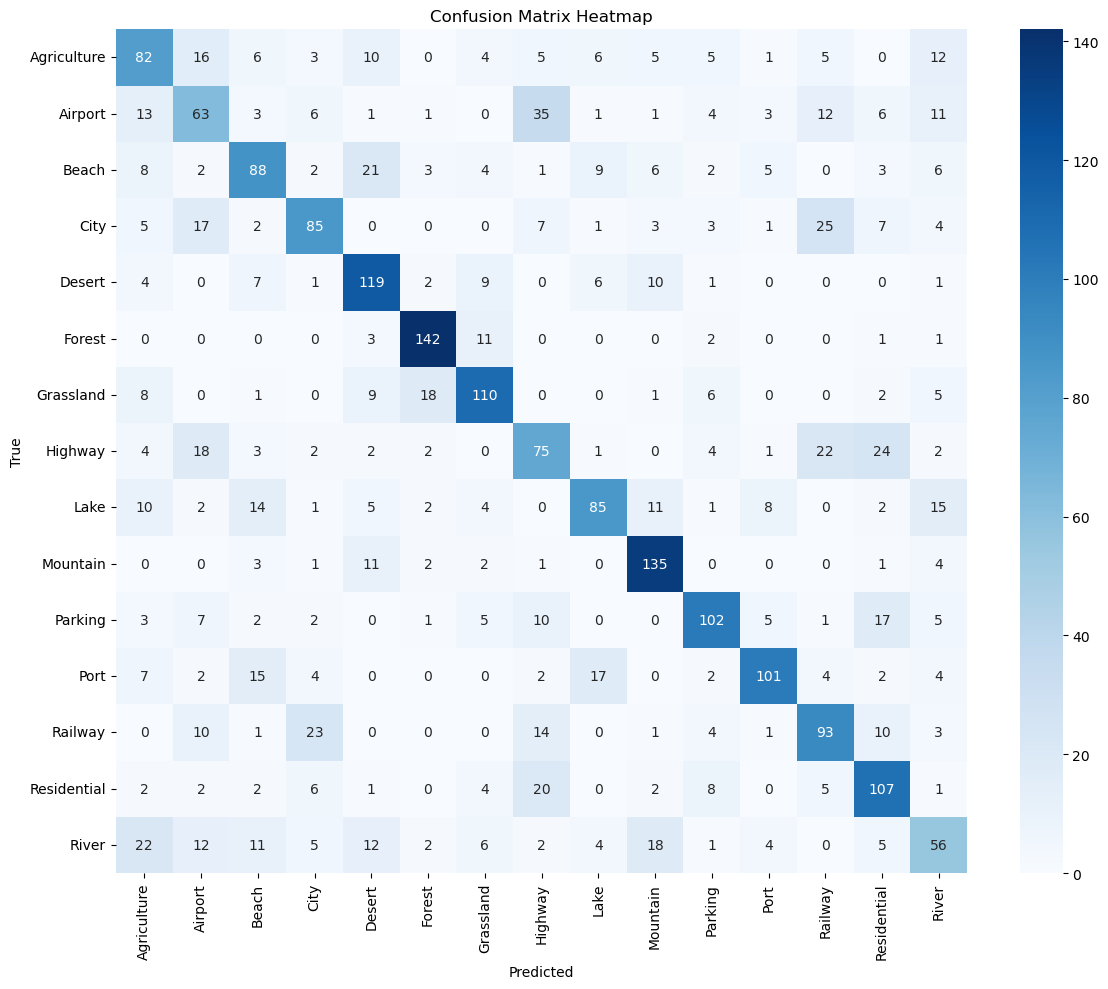

In [7]:
get_model_cm(y_test_svm, y_pred_svm, classes)

# Classifier Comparison

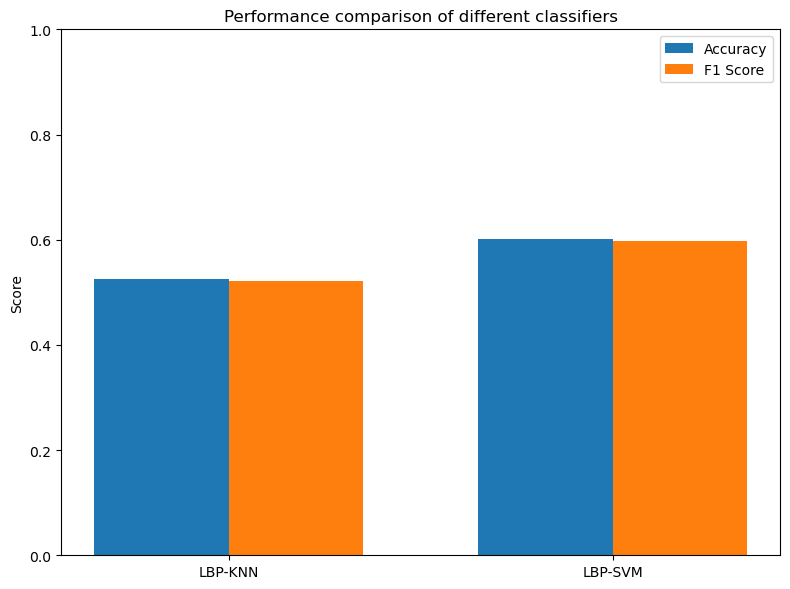

In [8]:
plot_model_comparison(score_dict)

# Robustness Test

## Test for LBP+SVM

  Model loading completed: classifier_svm.pkl
  Testing under perturbation: original


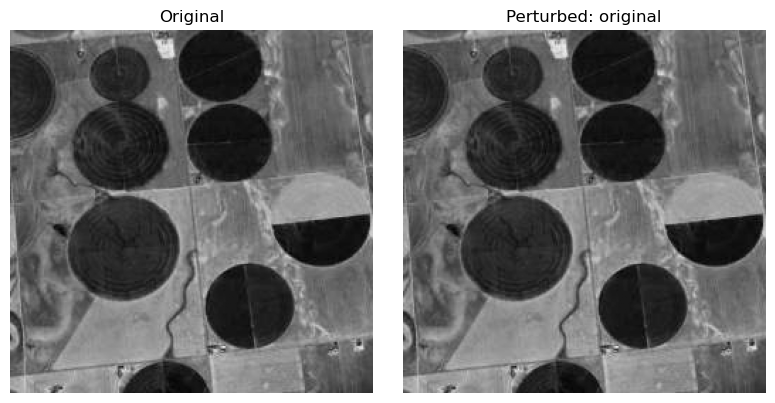

  Testing under perturbation: noise


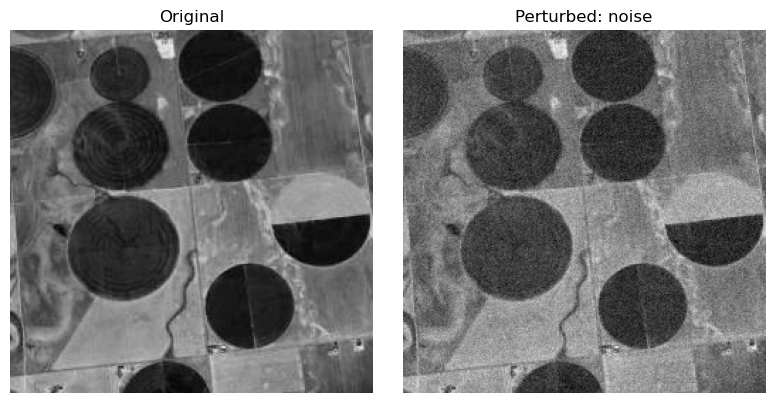

  Testing under perturbation: blur


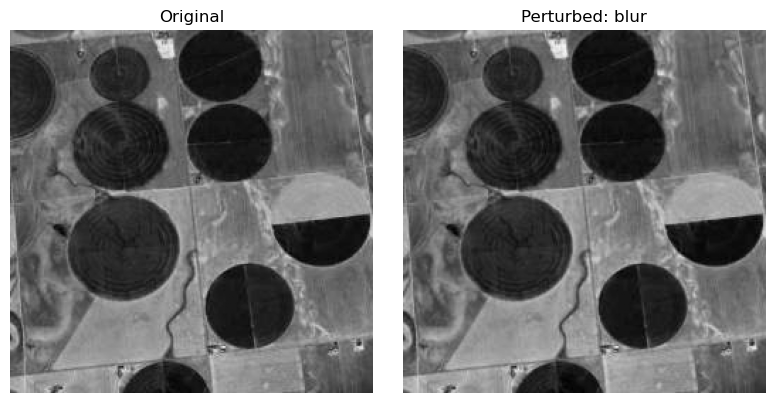

  Testing under perturbation: occlusion


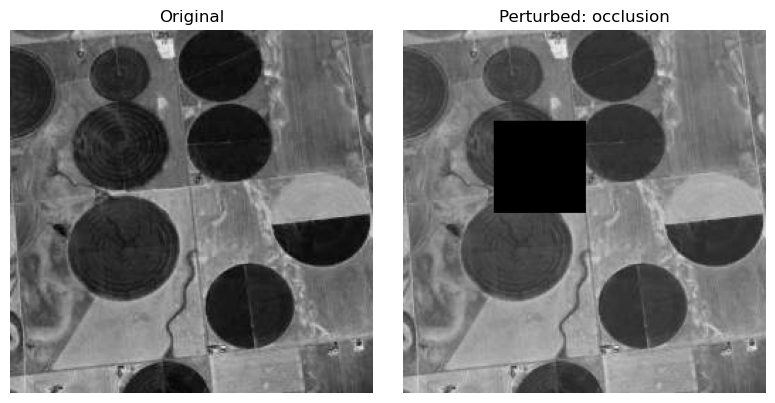

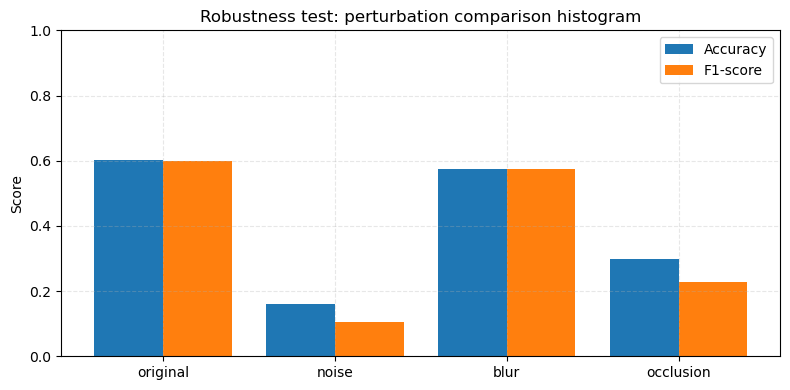

In [9]:
from core.evaluations import *
from lbp_robustness import *
from lbp_utils import apply_perturbation
modes, accs, f1s = test_robustness_with_saved_model(
    test_images, test_labels, classes, classifier_type="svm"
)
plot_robustness_bar_chart(modes, accs, f1s)

## Test for LBP+KNN

  Model loading completed: classifier_knn.pkl
  Testing under perturbation: original


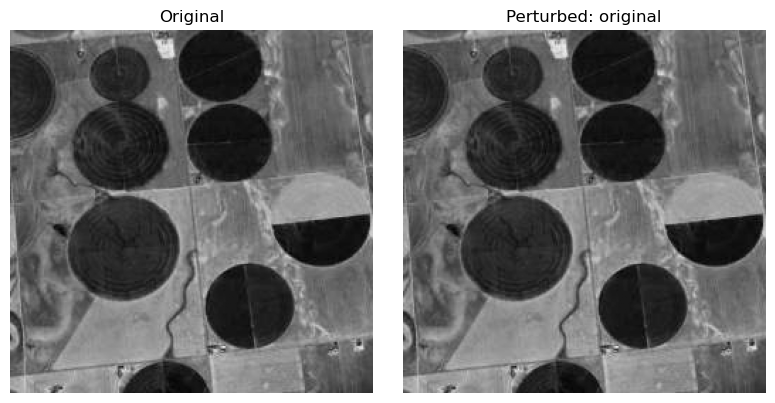

  Testing under perturbation: noise


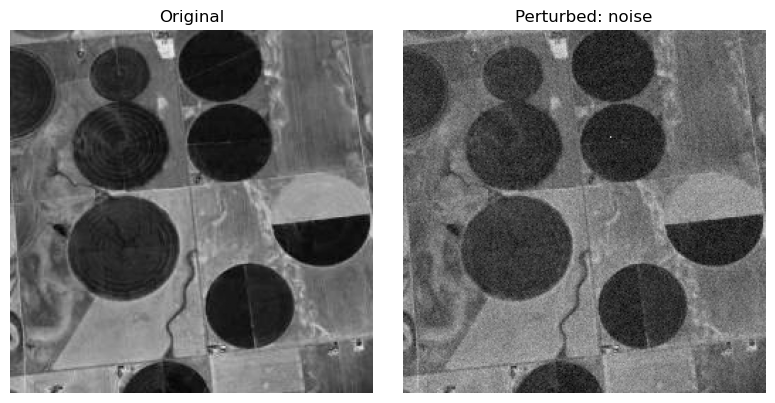

  Testing under perturbation: blur


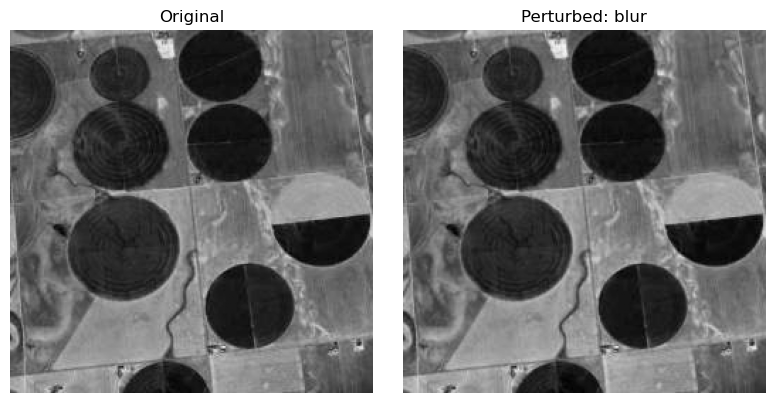

  Testing under perturbation: occlusion


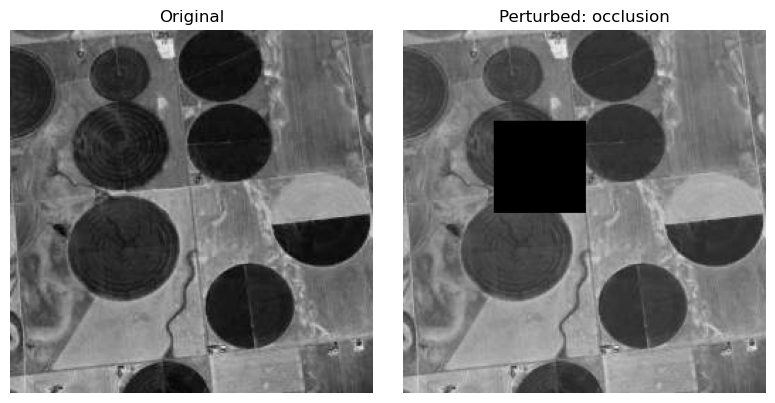

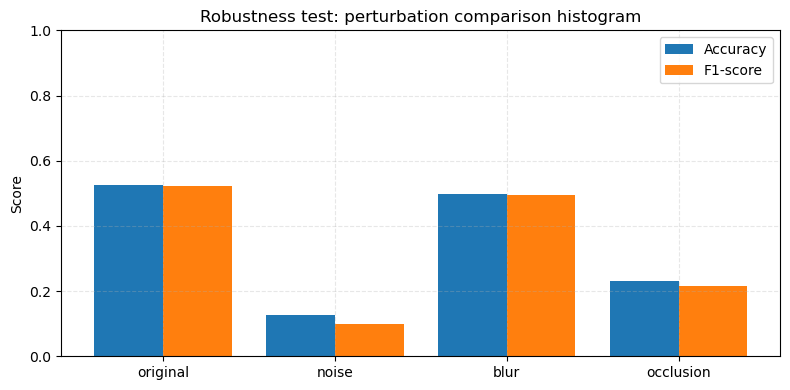

In [10]:
from core.evaluations import *
from lbp_robustness import *
from lbp_utils import apply_perturbation
modes, accs, f1s = test_robustness_with_saved_model(
    test_images, test_labels, classes, classifier_type="knn"
)
plot_robustness_bar_chart(modes, accs, f1s)

# Simulation of Imbalanced Experiment

## Load Dataset(50%)

In [3]:
import lbp_config as cfg
train_images, train_labels, test_images, test_labels, classes = sift_split_data(
    data_root=cfg.DATA_ROOT,
    test_ratio=cfg.TEST_SIZE,
    sample_ratio=0.5, 
    shuffle_seed=cfg.RANDOM_STATE,
    load_color_images=True
)

Total: 4800 training images, 1200 testing images


## Undersample

In [4]:
imbalance_setting = {
    0: 1.0,  # Agriculture
    1: 1.0,  # Airport
    2: 1.0,  # Beach
    3: 1.0,  # City
    4: 0.7,  # Desert
    5: 0.5,  # Forest
    6: 1.0,  # Grassland
    7: 1.0,  # Highway
    8: 1.0,  # Lake
    9: 0.5,  # Mountain
    10: 0.7, # Parking
    11: 0.6, # Port
    12: 1.0, # Railway
    13: 1.0, # Residential
    14: 1.0, # River
}
resampled_images, resampled_labels = simulate_imbalance_and_resample(
    train_images, train_labels,
    imbalance_ratio=imbalance_setting,
    resample_method="undersample", 
    random_state=42
)


scaler, clf = train_lbp_imbalanced_model(resampled_images, resampled_labels, classifier_type="svm")

y_test, y_pred, classes = test_lbp_model_imbalance(test_images, test_labels, scaler, clf, classes)

acc, f1 = get_model_score(y_test, y_pred, classes)

  Extract training set LBP features...


  Extract test set LBP features...

Model evaluation results: 
Accuracy: 0.5692
Precision: 0.5704
Recall: 0.5692
F1-score: 0.5655


## Oversample

In [5]:
imbalance_setting = {
    0: 1.0,  # Agriculture
    1: 1.0,  # Airport
    2: 1.0,  # Beach
    3: 1.0,  # City
    4: 0.7,  # Desert
    5: 0.5,  # Forest
    6: 1.0,  # Grassland
    7: 1.0,  # Highway
    8: 1.0,  # Lake
    9: 0.5,  # Mountain
    10: 0.7, # Parking
    11: 0.6, # Port
    12: 1.0, # Railway
    13: 1.0, # Residential
    14: 1.0, # River
}
resampled_images, resampled_labels = simulate_imbalance_and_resample(
    train_images, train_labels,
    imbalance_ratio=imbalance_setting,
    resample_method="oversample",  
    random_state=42
)

scaler, clf = train_lbp_imbalanced_model(resampled_images, resampled_labels, classifier_type="svm")

y_test, y_pred, classes = test_lbp_model_imbalance(test_images, test_labels, scaler, clf, classes)

acc, f1 = get_model_score(y_test, y_pred, classes)

  Extract training set LBP features...


  Extract test set LBP features...

Model evaluation results: 
Accuracy: 0.5567
Precision: 0.5590
Recall: 0.5567
F1-score: 0.5528


# References

scikit-learn Documentation
Used for implementing classification models (SVM, KNN), scaling (StandardScaler), evaluation (classification_report, confusion_matrix) and dataset splitting.
https://scikit-learn.org/stable/documentation.html

OpenCV Official Documentation
Utilized for image processing operations such as cv2.SIFT_create, detectAndCompute, cv2.add, GaussianBlur, and cvtColor.
https://docs.opencv.org/4.x/

scikit-image Documentation
Used for implementing Local Binary Pattern (LBP) via skimage.feature.local_binary_pattern.
https://scikit-image.org/docs/stable/

PyImageSearch Tutorials
Inspired the structure and logic of SIFT, Bag of Visual Words (BoW), and visual feature extraction techniques.
https://pyimagesearch.com

General Kaggle & Course Practices
The evaluation design (e.g., side-by-side comparisons of models and features, heatmaps, bar charts) follows best practices found in many academic labs and Kaggle notebooks.
